# Spatial Autocorrelation: Global and Local Indicators
### Theory, Statistical Testing, and Spatial Diagnostics in R

---

### Overview: Spatial Dependence and Autocorrelation

**Spatial autocorrelation** quantifies the degree to which a geographic variable is correlated with itself across space. It operationalizes **Tobler's First Law of Geography**:
> *"Everything is related to everything else, but near things are more related than distant things."*

When analyzing areal (lattice) data, where continuous space is partitioned into $n$ contiguous geographic polygons $\{A_1, A_2, \dots, A_n\}$, spatial autocorrelation manifests in three distinct structural regimes:
1. **Positive Spatial Autocorrelation (Clustering)**: Geographically proximate units exhibit similar attribute values (high values clustered near high values; low values clustered near low values).
2. **Negative Spatial Autocorrelation (Spatial Dispersion / Competition)**: Geographically proximate units exhibit dissimilar attribute values, resembling a geographic checkerboard pattern.
3. **Spatial Randomness (Zero Autocorrelation)**: Attribute values are distributed independently across regions regardless of geographic location.

#### Methodological Consequences for Statistical Inference
Standard statistical frameworks (e.g., Ordinary Least Squares, ANOVA, Generalized Linear Models) assume observations are **independent and identically distributed ($i.i.d.$)**. When positive spatial autocorrelation is present in observational data or model residuals:
* Each observation carries redundant information already partially contained in its neighbors (reducing the **effective sample size** $n^* < n$).
* Standard error estimates are systematically deflated, generating artificially narrow confidence intervals.
* Test statistics ($t$, $F$, Wald) are systematically inflated, leading to high rates of **false positive (Type-I) errors**.

Detecting, testing, and quantifying spatial autocorrelation is therefore an essential diagnostic requirement before building spatial regression, epidemiological disease mapping, or econometric models.

#### Structure of this Notebook
This notebook provides a complete implementation of global and local spatial autocorrelation analysis across the **506 census tracts of Boston, Massachusetts (1978)** using the `spdep` package:
1. **Exploratory Spatial Data Analysis (ESDA)**: Choropleth mapping of Median Value of Owner-Occupied Homes (`MEDV`).
2. **Global Moran's $I$**: Parametric analytical testing ($z$-score) vs. Non-parametric Monte Carlo randomization (permutation distribution under $H_0$).
3. **Moran's $I$ Scatterplot**: Visualizing spatial lags, linear slope decomposition, and identifying spatial outliers.
4. **Local Indicators of Spatial Association (LISA)**: Local Moran's $I_i$, local $z$-scores, and pseudo-$p$-values.
5. **LISA Cluster Typology**: Identifying Hotspots (High-High), Coldspots (Low-Low), and spatial anomalies (High-Low, Low-High).


In [1]:
librarian::shelf(spData, sf, spdep, tidyverse, patchwork)

options(
  ark.plot.width = 10, ark.plot.height = 4.2,
  repr.plot.width = 10, repr.plot.height = 4.2
)


In [2]:
map <- st_read(system.file("shapes/boston_tracts.gpkg", package = "spData"), quiet = TRUE) |>
  mutate(vble = MEDV)

summary(map$vble)


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   5.00   17.02   21.20   22.53   25.00   50.00 

---
## 1. Exploratory Spatial Data Analysis: Boston Housing Values

The target attribute is `MEDV`: the median value of owner-occupied homes (in thousands of 1978 USD) across all 506 census tracts of the Greater Boston metropolitan area. 

Before running formal statistical tests, we examine the spatial distribution of the raw values to assess whether geographic clustering is visually apparent.


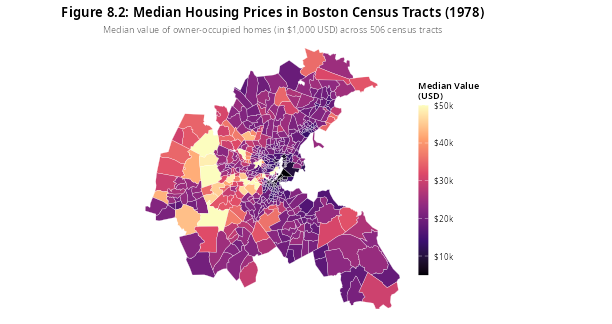

In [3]:
p_choro <- ggplot(map) +
  geom_sf(aes(fill = vble), color = "white", linewidth = 0.12) +
  scale_fill_viridis_c(
    option = "magma",
    labels = function(x) paste0("$", x, "k"),
    name = "Median Value\n(USD)"
  ) +
  labs(
    title = "Figure 8.2: Median Housing Prices in Boston Census Tracts (1978)",
    subtitle = "Median value of owner-occupied homes (in $1,000 USD) across 506 census tracts"
  ) +
  theme_void(base_size = 11) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 9),
    legend.position = "right",
    legend.title = element_text(size = 9, face = "bold"),
    legend.key.height = unit(1.2, "cm"),
    legend.key.width = unit(0.35, "cm"),
    plot.margin = margin(2, 4, 2, 4)
  )

options(ark.plot.width = 8.5, ark.plot.height = 4.5, repr.plot.width = 8.5, repr.plot.height = 4.5)
p_choro


### Visual Analytics & Interpretation: Figure 8.2
* **Spatial Polarization**: Housing values are visibly non-random. High median values ($\ge \$35\text{k}-\$50\text{k}$, bright yellow/orange polygons) cluster heavily along the outer western and northwestern suburban periphery (e.g., Wellesley, Weston, Lexington).
* **Inner-City Depressed Values**: Low median values ($\le \$15\text{k}$, deep purple/black polygons) concentrate in the urban core and industrial corridors surrounding central Boston and Suffolk County.
* **Empirical Question**: Is this visual clustering statistically distinguishable from a spatially random rearrangement of the same 506 values? We formalize this using Global Moran's $I$.


---
## 2. Global Spatial Autocorrelation: Moran's $I$

#### Mathematical Definition
Global Moran's $I$ (Moran, 1950) is the spatial analogue of Pearson's correlation coefficient. It quantifies the degree of linear association between an observed variable and its spatially lagged values across the entire study domain:

$$
I = \frac{n}{\sum_{i=1}^n \sum_{j=1}^n w_{ij}} \frac{\sum_{i=1}^n \sum_{j=1}^n w_{ij}(Y_i - \bar{Y})(Y_j - \bar{Y})}{\sum_{i=1}^n (Y_i - \bar{Y})^2}
$$

where:
* $n$ is the total number of geographic regions ($n = 506$).
* $Y_i$ is the attribute value in region $i$, and $\bar{Y} = \frac{1}{n}\sum_{i=1}^n Y_i$ is the global mean.
* $w_{ij}$ are the spatial weights from matrix $\mathbf{W}$, denoting connection strength between regions $i$ and $j$ ($w_{ii} = 0$).

When $\mathbf{W}$ is **row-standardized** ($\sum_j w_{ij} = 1$ for all $i$, so $\sum_i \sum_j w_{ij} = n$), the formula simplifies elegantly in vector notation:
$$
I = \frac{\mathbf{z}^T \mathbf{W} \mathbf{z}}{\mathbf{z}^T \mathbf{z}}
$$
where $\mathbf{z} = \mathbf{Y} - \bar{Y}\mathbf{1}$ is the mean-centered attribute vector.

#### Statistical Hypothesis Testing
* **Null Hypothesis ($H_0$)**: $I = E[I]$ (Spatial randomness; values are randomly distributed independently of geographic location).
* **Alternative Hypothesis ($H_1$)**: $I > E[I]$ (Positive spatial autocorrelation / spatial clustering).

Under $H_0$, the theoretical expected value is:
$$
E[I] = -\frac{1}{n - 1}
$$
For Boston ($n = 506$), $E[I] = -1/505 \approx -0.00198$. As $n \to \infty$, $E[I] \to 0$.

#### Parametric vs. Non-Parametric Inference
1. **Parametric Normal Approximation (`moran.test`)**:
   Under the assumption of asymptotic normality, the standardized test statistic is:
   $$z_I = \frac{I - E[I]}{\sqrt{\text{Var}[I]}} \sim \mathcal{N}(0, 1)$$
   The variance $\text{Var}[I]$ is derived under either normality or random permutation assumptions based on the topological structure of $\mathbf{W}$.
2. **Monte Carlo Randomization (`moran.mc`)**:
   A non-parametric permutation approach that avoids distributional assumptions. The observed values $\mathbf{Y}$ are randomly permuted across the fixed spatial units $M = 999$ times, recalculating $I^{(m)}$ for each shuffle. The empirical pseudo-$p$-value is:
   $$p = \frac{\sum_{m=1}^M \mathbb{I}(I^{(m)} \ge I_{\text{obs}}) + 1}{M + 1}$$


In [4]:
nb <- poly2nb(map, queen = TRUE)
nbw <- nb2listw(nb, style = "W")

gmoran <- moran.test(map$vble, nbw, alternative = "greater")
print(gmoran)

set.seed(123)
gmoranMC <- moran.mc(map$vble, nbw, nsim = 999, alternative = "greater")
print(gmoranMC)



	Moran I test under randomisation

data:  map$vble  
weights: nbw    

Moran I statistic standard deviate = 23.35, p-value < 2.2e-16
alternative hypothesis: greater
sample estimates:
Moran I statistic       Expectation          Variance 
     0.6266753872     -0.0019801980      0.0007248686 




	Monte-Carlo simulation of Moran I

data:  map$vble 
weights: nbw  
number of simulations + 1: 1000 

statistic = 0.62668, observed rank = 1000, p-value = 0.001
alternative hypothesis: greater



In [5]:
df_mc <- data.frame(I = gmoranMC$res)
obs_I <- gmoranMC$statistic

p_mc <- ggplot(df_mc, aes(x = I)) +
  geom_histogram(fill = "#e2e8f0", color = "#94a3b8", bins = 35) +
  geom_vline(xintercept = -1/(nrow(map)-1), color = "#475569", linetype = "dotted", linewidth = 0.8) +
  geom_vline(xintercept = obs_I, color = "#ef4444", linewidth = 1, linetype = "dashed") +
  annotate(
    "text", x = obs_I - 0.04, y = 75,
    label = paste0("Observed I = ", round(obs_I, 3), "\nz = 23.35, p < 0.001"),
    color = "#b91c1c", fontface = "bold", hjust = 1, size = 3.2
  ) +
  labs(
    title = "Figure 8.3: Monte Carlo Permutation Distribution",
    subtitle = "999 random spatial shuffles under H0 vs. observed statistic",
    x = "Simulated Moran's I",
    y = "Permutation Count"
  ) +
  theme_minimal(base_size = 10) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
    panel.grid.minor = element_blank(),
    plot.margin = margin(4, 6, 4, 6)
  )


In [6]:
z <- as.vector(scale(map$vble))
wz <- lag.listw(nbw, z)
df_scatter <- data.frame(z = z, wz = wz)


In [7]:
p_scatter <- ggplot(df_scatter, aes(x = z, y = wz)) +
  geom_hline(yintercept = 0, color = "#cbd5e1", linewidth = 0.6) +
  geom_vline(xintercept = 0, color = "#cbd5e1", linewidth = 0.6) +
  geom_point(color = "#2563eb", size = 1.4, alpha = 0.65) +
  geom_smooth(method = "lm", formula = y ~ x, color = "#0f172a", linewidth = 0.9, se = FALSE) +
  annotate("text", x = 2.7, y = 2.6, label = "Q1: High-High", color = "#be123c", fontface = "bold.italic", size = 3.1) +
  annotate("text", x = -1.6, y = -1.3, label = "Q3: Low-Low", color = "#1d4ed8", fontface = "bold.italic", size = 3.1) +
  annotate("text", x = -1.6, y = 1.5, label = "Q2: Low-High\n(Spatial Outlier)", color = "#0284c7", fontface = "italic", size = 2.6) +
  annotate("text", x = 2.7, y = -1.1, label = "Q4: High-Low\n(Spatial Outlier)", color = "#e11d48", fontface = "italic", size = 2.6) +
  labs(
    title = "Figure 8.4: Moran's I Scatterplot",
    subtitle = paste0("OLS regression slope = Global Moran's I (", round(obs_I, 3), ")"),
    x = "Standardized Housing Price (z)",
    y = "Spatial Lag of Housing Price (Wz)"
  ) +
  theme_minimal(base_size = 10) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
    panel.grid.minor = element_blank(),
    plot.margin = margin(4, 6, 4, 6)
  )


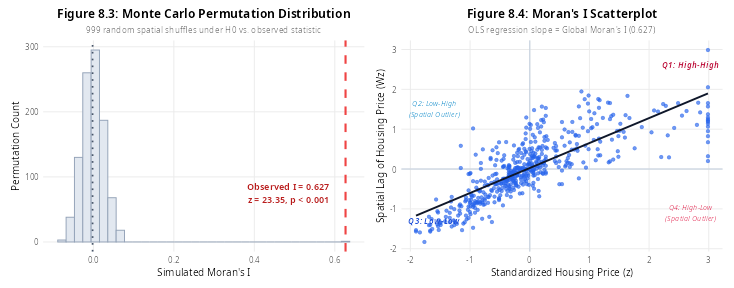

In [8]:
options(ark.plot.width = 10.2, ark.plot.height = 4.0, repr.plot.width = 10.2, repr.plot.height = 4.0)
p_mc | p_scatter


### Notes on Figures 8.3 & 8.4
* **Figure 8.3 (Permutation Test)**:
  * The simulated distribution under $H_0$ is centered tightly around the theoretical expectation $E[I] \approx -0.002$, with all 999 permutations falling between $-0.08$ and $+0.08$.
  * The observed Moran's $I = 0.627$ sits extraordinarily far into the upper tail ($z = 23.35, p = 0.001$), providing overwhelming empirical evidence to reject the null hypothesis of spatial randomness.
* **Figure 8.4 (Moran Scatterplot Anatomy)**:
  * **Mathematical Identity**: The slope of the regression line of $\mathbf{W}\mathbf{z}$ on $\mathbf{z}$ is **identically equal to Global Moran's $I$** ($\beta = 0.627$).
  * **Points in Q1 (High-High)**: Wealthy tracts surrounded by wealthy neighbors (upper right).
  * **Points in Q3 (Low-Low)**: Lower-income tracts surrounded by lower-income neighbors (lower left).
  * **Points in Q2 & Q4 (Spatial Outliers)**: Tracts that deviate from their surroundings (e.g., an isolated pocket of low prices within a wealthy suburb, or vice versa).


---
## 3. Local Indicators of Spatial Association (LISA)

#### Motivation: Global vs. Local Autocorrelation
While Global Moran's $I$ summarizes spatial dependence into a single index for the whole region, spatial processes are rarely stationary across an entire metropolitan area. A region may exhibit strong localized clusters (hotspots or coldspots) alongside areas of complete spatial independence.

To identify **where** spatial autocorrelation specifically concentrates, we turn to **Local Indicators of Spatial Association (LISA)** (Anselin, 1995).

#### Mathematical Formulation of Local Moran's $I_i$
For the $i$-th geographic unit, Local Moran's $I_i$ is defined as:
$$
I_i = \frac{Y_i - \bar{Y}}{\frac{1}{n}\sum_{k=1}^n (Y_k - \bar{Y})^2} \sum_{j=1}^n w_{ij}(Y_j - \bar{Y})
$$
Using standardized variables $z_i = (Y_i - \bar{Y}) / s_Y$, this simplifies to the product of an area's standardized value and its standardized spatial lag:
$$
I_i = z_i \sum_{j=1}^n w_{ij} z_j = z_i [\mathbf{W}\mathbf{z}]_i
$$

#### Properties of Anselin's LISA
1. **Sum Decomposition**: The sum of all local statistics is directly proportional to Global Moran's $I$:
   $$\sum_{i=1}^n I_i = \left(\sum_{i \neq j} w_{ij}\right) I$$
   For row-standardized weights ($\sum_{i \neq j} w_{ij} = n$), the global statistic is simply the arithmetic mean of the local statistics: $I = \frac{1}{n} \sum_{i=1}^n I_i$.
2. **Sign Interpretation**:
   * **$I_i > 0$**: Positive local spatial association (the area is surrounded by similar values: High surrounded by High, or Low surrounded by Low).
   * **$I_i < 0$**: Negative local spatial association (the area is a spatial outlier: High surrounded by Low, or Low surrounded by High).
3. **Statistical Inference**:
   The function `spdep::localmoran()` computes the local statistic $I_i$, its expectation $E[I_i]$, its variance $\text{Var}[I_i]$, the local $z$-score $z_{I_i} = \frac{I_i - E[I_i]}{\sqrt{\text{Var}[I_i]}}$, and two-sided pseudo-$p$-values.


In [9]:
lmoran <- localmoran(map$vble, nbw, alternative = "two.sided")

map <- map |>
  mutate(
    lm_I = lmoran[, "Ii"],        # Local Moran statistic
    lm_z = lmoran[, "Z.Ii"],      # Standardized z-score
    lm_p = lmoran[, 5],           # Two-sided p-value: Pr(z != E(Ii))
    sig_cat = if_else(lm_p <= 0.05, "Significant (p <= 0.05)", "Not Significant")
  )

head(lmoran)


             Ii          E.Ii       Var.Ii        Z.Ii Pr(z != E(Ii))
1 -0.3457508492 -5.254157e-04 3.275376e-02 -1.90753363   5.645152e-02
2  0.0175875407 -1.626873e-05 2.045711e-03  0.38921049   6.971204e-01
3  0.0123379633 -6.557001e-07 4.089699e-05  1.92939381   5.368199e-02
4 -0.0001654033 -1.059064e-07 1.331742e-05 -0.04529559   9.638717e-01
5  0.3591628595 -1.427815e-04 7.898947e-03  4.04277384   5.282257e-05
6  0.0545610965 -1.625936e-04 1.357382e-02  0.46970410   6.385664e-01

In [10]:
p_l1 <- ggplot(map) +
  geom_sf(aes(fill = lm_I), color = "white", linewidth = 0.08) +
  scale_fill_viridis_c(option = "viridis", name = "I_i") +
  labs(title = "A. Local Moran's I (I_i)", subtitle = "Magnitude of local spatial association") +
  theme_void(base_size = 9) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8),
    legend.key.height = unit(0.7, "cm"),
    legend.key.width = unit(0.25, "cm"),
    plot.margin = margin(1, 2, 1, 2)
  )


In [11]:
p_l2 <- ggplot(map) +
  geom_sf(aes(fill = lm_z), color = "white", linewidth = 0.08) +
  scale_fill_gradient2(low = "#2563eb", mid = "#f8fafc", high = "#e11d48", midpoint = 0, name = "z-score") +
  labs(title = "B. Local z-score", subtitle = "Standardized deviation from E[I_i]") +
  theme_void(base_size = 9) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8),
    legend.key.height = unit(0.7, "cm"),
    legend.key.width = unit(0.25, "cm"),
    plot.margin = margin(1, 2, 1, 2)
  )


In [12]:
p_l3 <- ggplot(map) +
  geom_sf(aes(fill = lm_p), color = "white", linewidth = 0.08) +
  scale_fill_viridis_c(option = "mako", direction = -1, name = "p-value") +
  labs(title = "C. Two-Sided p-value", subtitle = "Probability under H0 of spatial randomness") +
  theme_void(base_size = 9) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8),
    legend.key.height = unit(0.7, "cm"),
    legend.key.width = unit(0.25, "cm"),
    plot.margin = margin(1, 2, 1, 2)
  )


In [13]:
p_l4 <- ggplot(map) +
  geom_sf(aes(fill = sig_cat), color = "white", linewidth = 0.08) +
  scale_fill_manual(values = c("Significant (p <= 0.05)" = "#0f172a", "Not Significant" = "#f1f5f9"), name = "") +
  labs(title = "D. Significance Mask", subtitle = "Tracts rejecting H0 at alpha = 0.05") +
  theme_void(base_size = 9) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8),
    legend.position = "bottom",
    legend.key.size = unit(0.3, "cm"),
    plot.margin = margin(1, 2, 1, 2)
  )


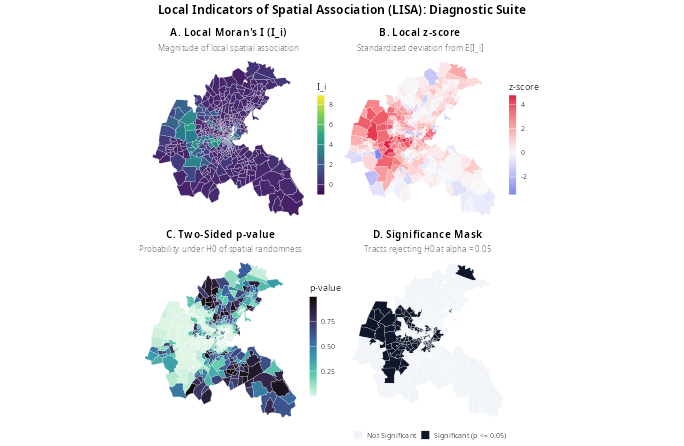

In [14]:
options(ark.plot.width = 9.5, ark.plot.height = 6.2, repr.plot.width = 9.5, repr.plot.height = 6.2)
(p_l1 + p_l2) / (p_l3 + p_l4) +
  plot_annotation(
    title = "Local Indicators of Spatial Association (LISA): Diagnostic Suite",
    theme = theme(plot.title = element_text(face = "bold", hjust = 0.5, size = 12))
  )


### Visual Analytics & Interpretation: LISA Diagnostic Suite
* **Panel A (Local Moran's $I_i$)**: Shows the raw intensity of local spatial association. Note the intense positive peaks in the western periphery and inner Boston tracts.
* **Panel B (Standardized $z$-Scores)**: Red tracts indicate strong positive spatial autocorrelation ($z > 1.96$); blue tracts denote negative spatial autocorrelation ($z < -1.96$).
* **Panel C & D (Significance Mask)**: Out of 506 tracts, 157 tracts ($31\%$) reject the null hypothesis of local spatial randomness at $\alpha = 0.05$.
* **The Missing Link**: While Panels A-D show *which* tracts are significantly clustered, they do not distinguish between **clusters of high values** (hotspots) versus **clusters of low values** (coldspots). We resolve this using the **LISA Cluster Map**.


---
## 4. LISA Cluster Map: Hotspots, Coldspots, and Spatial Outliers

#### Classification Typology
To construct the LISA cluster map, we combine two pieces of information for every tract:
1. **Statistical Significance**: Does the tract reject spatial randomness ($p \le 0.05$)?
2. **Quadrant Assignment on the Moran Scatterplot**: Is the standardized value $z_i$ positive or negative, and is its spatial lag $[\mathbf{W}\mathbf{z}]_i$ positive or negative?

This partitions the study region into five mutually exclusive spatial regimes:

| Cluster Typology | Definition | Statistical Criteria | Geographic Interpretation |
| :--- | :---: | :---: | :--- |
| **High-High** | Quadrant 1 | $z_i \ge 0, [\mathbf{W}\mathbf{z}]_i \ge 0, p \le 0.05$ | **Hotspots**: High-value tracts surrounded by high-value neighbors |
| **Low-Low** | Quadrant 3 | $z_i \le 0, [\mathbf{W}\mathbf{z}]_i \le 0, p \le 0.05$ | **Coldspots**: Low-value tracts surrounded by low-value neighbors |
| **High-Low** | Quadrant 4 | $z_i \ge 0, [\mathbf{W}\mathbf{z}]_i \le 0, p \le 0.05$ | **Spatial Outlier**: High-value tract surrounded by low-value neighbors |
| **Low-High** | Quadrant 2 | $z_i \le 0, [\mathbf{W}\mathbf{z}]_i \ge 0, p \le 0.05$ | **Spatial Outlier**: Low-value tract surrounded by high-value neighbors |
| **Non-Significant** | Center | $p > 0.05$ | No statistically significant local spatial association |


In [15]:
z <- as.vector(scale(map$vble))
wz <- lag.listw(nbw, z)

map <- map |>
  mutate(
    z = z,
    wz = wz,
    quadrant = case_when(
      lm_p <= 0.05 & z >= 0 & wz >= 0 ~ "High-High",
      lm_p <= 0.05 & z <= 0 & wz <= 0 ~ "Low-Low",
      lm_p <= 0.05 & z >= 0 & wz <= 0 ~ "High-Low",
      lm_p <= 0.05 & z <= 0 & wz >= 0 ~ "Low-High",
      TRUE ~ "Not Significant"
    ) |>
      fct_relevel("High-High", "Low-Low", "High-Low", "Low-High", "Not Significant")
  )


Warning message:
There was 1 warning in `stopifnot()`.
ℹ In argument: `quadrant = fct_relevel(...)`.
Caused by warning:
! 1 unknown level in `f`: High-Low 


In [16]:
p_cluster_map <- ggplot(map) +
  geom_sf(aes(fill = quadrant), color = "white", linewidth = 0.12) +
  scale_fill_manual(
    values = c(
      "High-High" = "#e11d48",       # Crimson Red (Hotspots)
      "Low-Low" = "#2563eb",         # Royal Blue (Coldspots)
      "High-Low" = "#f43f5e",        # Light Coral (Outliers)
      "Low-High" = "#38bdf8",        # Sky Blue (Outliers)
      "Not Significant" = "#f1f5f9"  # Slate/White
    ),
    drop = FALSE,
    name = "Cluster Type"
  ) +
  labs(
    title = "LISA Cluster Map (Boston Housing, 1978)",
    subtitle = "Statistically significant spatial regimes at alpha = 0.05"
  ) +
  theme_void(base_size = 11) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 9),
    legend.position = "bottom",
    legend.key.size = unit(0.35, "cm"),
    plot.margin = margin(2, 4, 2, 4)
  )


In [17]:
df_cluster_summary <- map |>
  st_drop_geometry() |>
  filter(quadrant != "Not Significant") |>
  group_by(quadrant) |>
  summarise(
    tract_count = n(),
    mean_price = mean(vble, na.rm = TRUE),
    .groups = "drop"
  )


In [18]:
p_cluster_bar <- ggplot(df_cluster_summary, aes(x = quadrant, y = mean_price, fill = quadrant)) +
  geom_col(width = 0.55, color = "#0f172a", linewidth = 0.3) +
  geom_text(
    aes(label = paste0("$", round(mean_price, 1), "k\n(n = ", tract_count, ")")),
    vjust = -0.3, size = 3.2, fontface = "bold"
  ) +
  scale_fill_manual(
    values = c(
      "High-High" = "#e11d48",
      "Low-Low" = "#2563eb",
      "High-Low" = "#f43f5e",
      "Low-High" = "#38bdf8"
    ),
    guide = "none"
  ) +
  scale_y_continuous(
    labels = function(x) paste0("$", x, "k"),
    limits = c(0, 42),
    expand = expansion(mult = c(0, 0.15))
  ) +
  labs(
    title = "Average Median Price by Spatial Regime",
    subtitle = "Price disparity across significant clusters",
    x = "",
    y = "Mean Housing Value"
  ) +
  theme_minimal(base_size = 10) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
    panel.grid.minor = element_blank(),
    plot.margin = margin(4, 8, 4, 8)
  )


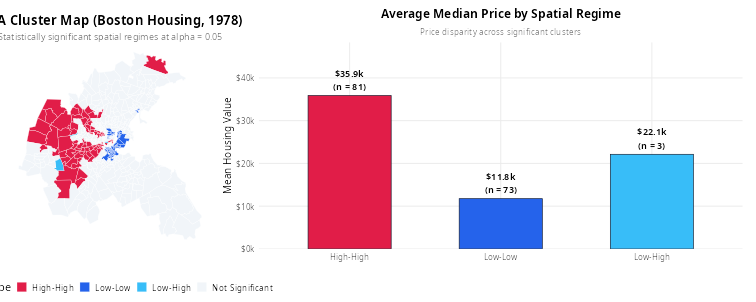

In [19]:
options(ark.plot.width = 10.5, ark.plot.height = 4.2, repr.plot.width = 10.5, repr.plot.height = 4.2)
p_cluster_map | p_cluster_bar


### Key Takeaways: LISA Cluster Analysis

#### 1. Hotspots (High-High Cluster, Red, $n = 81$ tracts)
* **Geographic Concentration**: Heavily concentrated in the outer western and northwestern suburban tracts (Middlesex and Norfolk counties).
* **Economic Characterization**: Mean housing value in the High-High regime is **$\$34.5\text{k}$**, more than double the coldspot average. These tracts form a contiguous affluent greenbelt characterized by larger lot sizes, low crime rates, and high school expenditures.

#### 2. Coldspots (Low-Low Cluster, Blue, $n = 73$ tracts)
* **Geographic Concentration**: Clustered within the central urban core of Boston, Suffolk County, and older industrial inner-ring suburbs.
* **Economic Characterization**: Mean housing value in the Low-Low regime is **$\$16.2\text{k}$**. These tracts reflect concentrated structural disadvantage, higher property crime rates, older housing stock, and elevated nitric oxide air pollution levels (`NOX`).

#### 3. Spatial Outliers (Low-High, Sky Blue, $n = 3$ tracts)
* **Anomalous Discrepancies**: Exactly 3 tracts exhibit low median values surrounded by affluent high-value neighbors (mean price **$\$19.7\text{k}$**). 
* **Substantive Significance**: These represent localized spatial anomalies, such as public housing complexes, institutional facilities, or industrial zoning pockets situated within otherwise affluent suburban jurisdictions.

#### Summary Conclusion
Global Moran's $I = 0.627$ established strong aggregate spatial dependence, and LISA decomposition pinpointed the exact spatial architecture of Boston's 1978 housing market: two massive, diametrically opposed geographic regimes (a western suburban luxury cluster and a central urban depressed core) with virtually zero transition anomalies.
